# Chapter 1, Problem 18 — velocity parameters (rapidity) add linearly

**Problem (paraphrased).**
- **(a)** Define the velocity parameter $u$ by $v = \tanh u$; for $-\infty < u < \infty$ the velocity stays within $-1 < v < 1$. Show that if $v = \tanh u$ and $w = \tanh U$, then the velocity-composition law Eq. (1.13) gives $w' = \tanh(u + U)$: velocity parameters add linearly.
- **(b)** A star measures a second star moving away at $0.9c$. The second star measures a third receding in the same direction at $0.9c$; the third measures a fourth, and so on up to some large number $N$ of stars. What is the velocity of the $N$th star relative to the first? Give an exact answer and an approximation for large $N$.

(The extracted text prints "$w = \tanh(u+U)$"; the composed velocity is $w'$ in Eq. (1.13)'s notation, $W' = (W + v)/(1 + Wv)$.)

## (a) Composition law ⇔ addition of rapidities

**Hyperbolic addition formula.** From $\tanh x = \sinh x/\cosh x$ and
$$
\sinh(u+U) = \sinh u\cosh U + \cosh u\sinh U,\qquad \cosh(u+U) = \cosh u\cosh U + \sinh u\sinh U,
$$
divide numerator and denominator by $\cosh u\cosh U$:
$$
\tanh(u + U) = \frac{\tanh u + \tanh U}{1 + \tanh u\tanh U}.
$$

**Compare with Eq. (1.13).** A particle has velocity $w$ in $\bar{\mathcal O}$, which moves at $v$ relative to $\mathcal O$. Then
$$
w' = \frac{w + v}{1 + wv} = \frac{\tanh U + \tanh u}{1 + \tanh U\tanh u} = \tanh(u + U).\qquad\blacksquare
$$

So with $v = \tanh u$, $w = \tanh U$, $w' = \tanh U'$: $\boxed{U' = u + U}$.

**Why the range works.** $\tanh$ maps $(-\infty, \infty)$ one-to-one onto $(-1, 1)$, so every subluminal velocity has exactly one rapidity, and *any* sum of rapidities maps back to a subluminal velocity. The "can't exceed $c$" property of Eq. (1.13) becomes trivial: you can add rapidities forever and $\tanh$ never reaches 1. For small values $\tanh u \approx u$, so rapidity ≈ velocity and linear addition reduces to Galilean addition.

In [1]:
import sympy as sp
u, U = sp.symbols("u U", real=True)
lhs = sp.tanh(u + U)
rhs = (sp.tanh(u) + sp.tanh(U)) / (1 + sp.tanh(u)*sp.tanh(U))
print("tanh(u+U) − (tanh u + tanh U)/(1 + tanh u tanh U) =", sp.simplify((lhs - rhs).rewrite(sp.exp)))

tanh(u+U) − (tanh u + tanh U)/(1 + tanh u tanh U) = 0


## (b) The chain of stars

**Rapidity of one step.** Each star sees the next receding at $0.9$:
$$
u_1 = \tanh^{-1}(0.9) = \tfrac12\ln\frac{1 + 0.9}{1 - 0.9} = \tfrac12\ln 19 \approx 1.4722 .
$$
(Using $\tanh^{-1}x = \tfrac12\ln\frac{1+x}{1-x}$.)

**Star 1 → star $N$.** There are $N - 1$ steps, all in the same direction, so their rapidities add:
$$
U_N = (N - 1)\,u_1 = \frac{N-1}{2}\ln 19 .
$$

**Back to velocity.** Using $\tanh U = \dfrac{e^{2U} - 1}{e^{2U} + 1}$ and $e^{2U_N} = e^{(N-1)\ln19} = 19^{\,N-1}$:
$$
\boxed{\,v_N = \tanh\!\big((N-1)\tanh^{-1}0.9\big) = \frac{19^{\,N-1} - 1}{19^{\,N-1} + 1}\,}
$$

**Checks.** $N = 1$: $v = 0$ ✓ (a star relative to itself). $N = 2$: $18/20 = 0.9$ ✓. $N = 3$: $360/362 = 0.99448$; directly from Eq. (1.13), $(0.9 + 0.9)/(1 + 0.81) = 1.8/1.81 = 0.99448$ ✓.

**Large $N$.** Write $v_N = \dfrac{1 - 19^{-(N-1)}}{1 + 19^{-(N-1)}}$ and expand with $\delta = 19^{-(N-1)} \ll 1$: $(1-\delta)(1 - \delta + \dots) \approx 1 - 2\delta$.
$$
\boxed{\,v_N \approx 1 - 2\times19^{-(N-1)}\,}\qquad(N\gg1)
$$
The gap to light speed shrinks by a factor 19 with every star, but never reaches zero. After 10 stars, $1 - v \approx 2\times19^{-9} \approx 6.9\times10^{-12}$.

(If "$N$ stars" is read as $N$ steps beyond the first star, replace $N-1$ by $N$ throughout: $v = (19^N - 1)/(19^N + 1)$.)

In [2]:
import numpy as np
from schutz_gr import velocity_seen_by
def compose(w, v):  # Eq. (1.13)
    return (w + v) / (1 + w * v)

print(f"{'N':>3s} {'exact (19^(N-1)−1)/(19^(N-1)+1)':>34s} {'repeated Eq.1.13':>18s} {'1 − v':>12s} {'approx 2·19^-(N-1)':>20s}")
vel = 0.0
for N in range(1, 11):
    if N > 1:
        vel = compose(vel, 0.9)
    k = sp.Integer(19)**(N - 1)
    exact = (k - 1) / (k + 1)
    print(f"{N:3d} {float(exact):34.15f} {vel:18.15f} {float(1 - exact):12.3e} {2*19.0**-(N-1):20.3e}")

  N    exact (19^(N-1)−1)/(19^(N-1)+1)   repeated Eq.1.13        1 − v   approx 2·19^-(N-1)
  1                  0.000000000000000  0.000000000000000    1.000e+00            2.000e+00
  2                  0.900000000000000  0.900000000000000    1.000e-01            1.053e-01
  3                  0.994475138121547  0.994475138121547    5.525e-03            5.540e-03
  4                  0.999708454810496  0.999708454810496    2.915e-04            2.916e-04
  5                  0.999984653396971  0.999984653396971    1.535e-05            1.535e-05
  6                  0.999999192278179  0.999999192278179    8.077e-07            8.077e-07
  7                  0.999999957488309  0.999999957488309    4.251e-08            4.251e-08
  8                  0.999999997762543  0.999999997762542    2.237e-09            2.237e-09
  9                  0.999999999882239  0.999999999882239    1.178e-10            1.178e-10
 10                  0.999999999993802  0.999999999993802    6.198e-12          

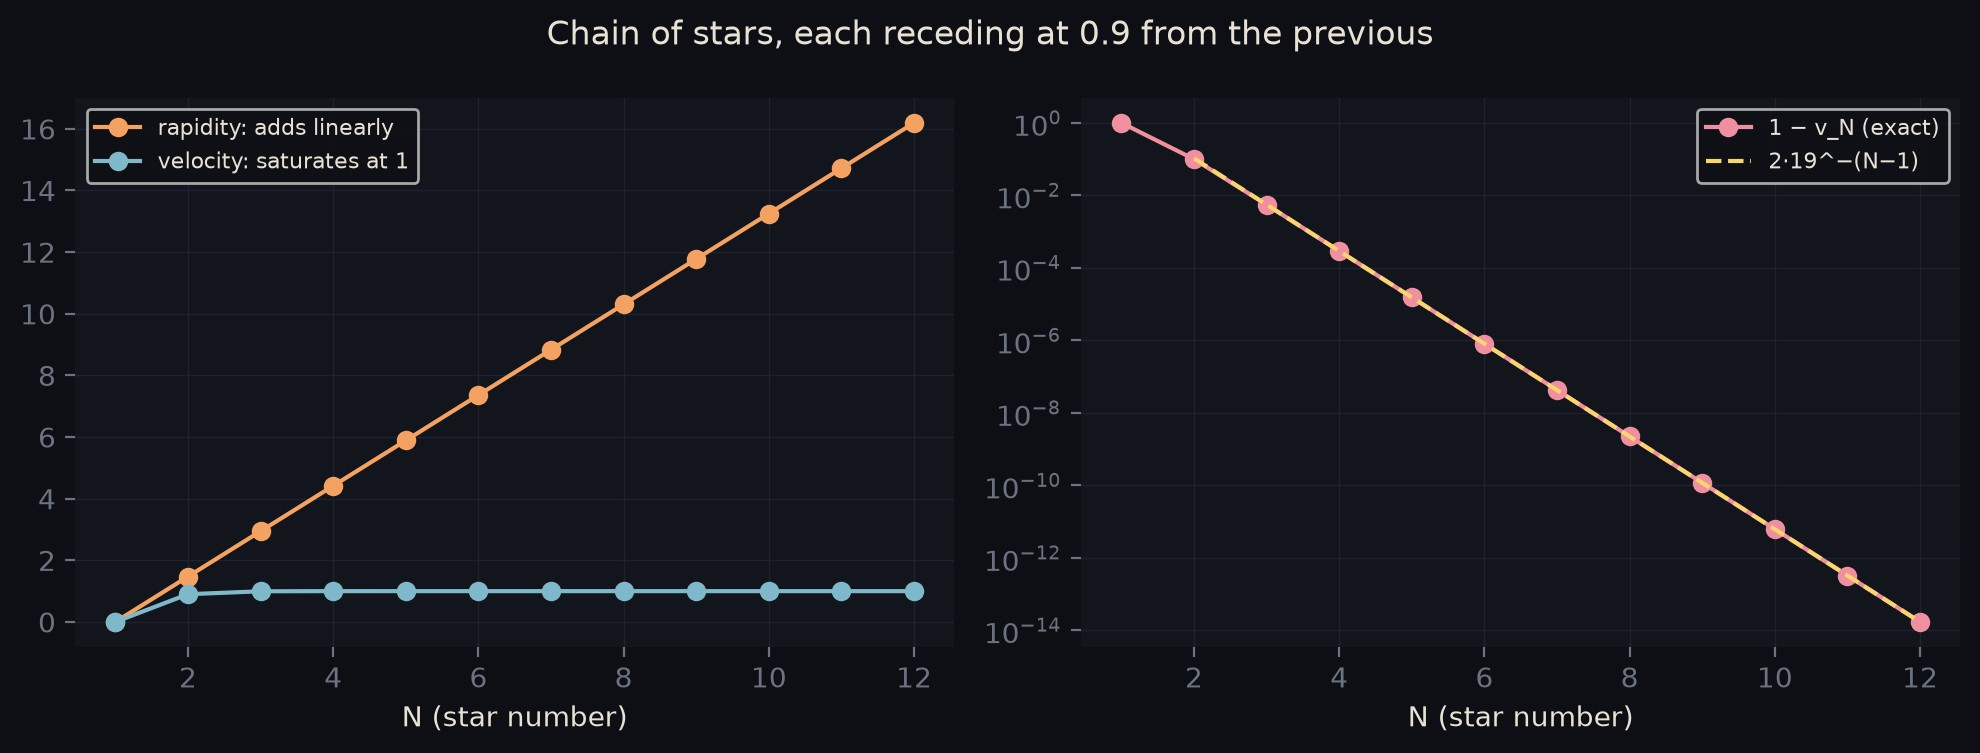

In [3]:
import matplotlib.pyplot as plt
from schutz_gr.diagrams import COLORS
%config InlineBackend.figure_format = 'retina'
N = np.arange(1, 13)
gap = 2 / (19.0**(N - 1) + 1)                 # 1 − v_N exactly
fig, axs = plt.subplots(1, 2, figsize=(10, 3.8)); fig.patch.set_facecolor(COLORS["bg"])
axs[0].plot(N, (N - 1) * np.arctanh(0.9), "o-", color=COLORS["amber"], label="rapidity: adds linearly")
axs[0].plot(N, np.tanh((N - 1) * np.arctanh(0.9)), "o-", color=COLORS["teal"], label="velocity: saturates at 1")
axs[1].semilogy(N, gap, "o-", color=COLORS["rose"], label="1 − v_N (exact)")
axs[1].semilogy(N[1:], 2 * 19.0**-(N[1:] - 1), "--", color=COLORS["gold"], label="2·19^−(N−1)")
for ax in axs:
    ax.set_facecolor(COLORS["panel"]); ax.tick_params(colors=COLORS["grey"]); ax.grid(color=COLORS["grid"], lw=0.5)
    ax.set_xlabel("N (star number)", color=COLORS["text"])
    for s in ax.spines.values(): s.set_visible(False)
    leg = ax.legend(fontsize=8); leg.get_frame().set_facecolor(COLORS["bg"])
    for t in leg.get_texts(): t.set_color(COLORS["text"])
fig.suptitle("Chain of stars, each receding at 0.9 from the previous", color=COLORS["text"])
plt.tight_layout(); plt.show()